# 03 — Stellar Kinematics Extraction (MaNGA DR17)

**Target:** `8138-12704`  
**DAPTYPE:** `HYB10-MILESHC-MASTARSSP`

## Objectives
1. Load stellar velocity, raw velocity dispersion, inverse variance, correction, and quality-mask extensions from the MAPS file.
2. Decode the important DAP mask bits.
3. Construct science masks for velocity and corrected dispersion.
4. Produce first-pass stellar velocity and velocity-dispersion maps.
5. Save numerical arrays and figures for the next analysis milestone.

**Important:** `STELLAR_SIGMA` is the raw measured dispersion. The astrophysically corrected value uses the first channel of `STELLAR_SIGMACORR`. Negative values under the square root are invalid and will be masked, not clipped to zero.

This notebook uses the existing project layout. Run it from the project notebook folder or let the path-detection cell locate the project root.

## 1. Imports and plotting configuration

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

plt.rcParams.update({
    "figure.figsize": (8, 6),
    "image.origin": "lower",
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "figure.dpi": 110,
})
np.set_printoptions(precision=3, suppress=True)

## 2. Locate the project and MAPS file

In [2]:
# Expected project structure:
# manga-stellar-kinematics/
#   data/raw/
#   data/processed/
#   outputs/figures/

candidate_roots = [
    Path.cwd(),
    Path.cwd().parent,
    Path(r"D:\\KS\\manga-stellar-kinematics"),
]

PROJECT_ROOT = next(
    (p.resolve() for p in candidate_roots
     if (p / "data" / "raw").is_dir()),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate project root. Set PROJECT_ROOT manually "
        "to your manga-stellar-kinematics folder."
    )

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

maps_matches = list(RAW_DIR.glob(
    "manga-8138-12704-MAPS-HYB10-MILESHC-MASTARSSP.fits*"
))
if len(maps_matches) != 1:
    raise FileNotFoundError(
        f"Expected exactly one MAPS file, found {len(maps_matches)}: "
        f"{maps_matches}"
    )

MAPS_PATH = maps_matches[0]
print("Project root:", PROJECT_ROOT)
print("MAPS file:", MAPS_PATH)

Project root: D:\KS\manga-stellar-kinematics
MAPS file: D:\KS\manga-stellar-kinematics\data\raw\manga-8138-12704-MAPS-HYB10-MILESHC-MASTARSSP.fits.gz


## 3. Open MAPS and verify the required extensions

In [3]:
maps = fits.open(MAPS_PATH, memmap=True)

required_extensions = [
    "STELLAR_VEL",
    "STELLAR_VEL_IVAR",
    "STELLAR_VEL_MASK",
    "STELLAR_SIGMA",
    "STELLAR_SIGMA_IVAR",
    "STELLAR_SIGMA_MASK",
    "STELLAR_SIGMACORR",
]

available = {hdu.name.upper() for hdu in maps}
missing = [name for name in required_extensions if name not in available]
if missing:
    maps.close()
    raise KeyError(f"Required MAPS extensions are missing: {missing}")

for name in required_extensions:
    hdu = maps[name]
    print(
        f"{name:22s} shape={hdu.data.shape!s:16s} "
        f"BUNIT={hdu.header.get('BUNIT', 'not recorded')} "
        f"QUALDATA={hdu.header.get('QUALDATA', 'not recorded')}"
    )

STELLAR_VEL            shape=(72, 72)         BUNIT=km/s QUALDATA=STELLAR_VEL_MASK
STELLAR_VEL_IVAR       shape=(72, 72)         BUNIT=(km/s)^{-2} QUALDATA=STELLAR_VEL_MASK
STELLAR_VEL_MASK       shape=(72, 72)         BUNIT=not recorded QUALDATA=not recorded
STELLAR_SIGMA          shape=(72, 72)         BUNIT=km/s QUALDATA=STELLAR_SIGMA_MASK
STELLAR_SIGMA_IVAR     shape=(72, 72)         BUNIT=(km/s)^{-2} QUALDATA=STELLAR_SIGMA_MASK
STELLAR_SIGMA_MASK     shape=(72, 72)         BUNIT=not recorded QUALDATA=not recorded
STELLAR_SIGMACORR      shape=(2, 72, 72)      BUNIT=km/s QUALDATA=not recorded


## 4. Read arrays and inspect their shapes

In [4]:
vel = np.asarray(maps["STELLAR_VEL"].data, dtype=float)
vel_ivar = np.asarray(maps["STELLAR_VEL_IVAR"].data, dtype=float)
vel_mask = np.asarray(maps["STELLAR_VEL_MASK"].data)

sigma_raw = np.asarray(maps["STELLAR_SIGMA"].data, dtype=float)
sigma_ivar = np.asarray(maps["STELLAR_SIGMA_IVAR"].data, dtype=float)
sigma_mask = np.asarray(maps["STELLAR_SIGMA_MASK"].data)

sigma_corr_hdu = maps["STELLAR_SIGMACORR"]
sigma_corr_all = np.asarray(sigma_corr_hdu.data, dtype=float)

print("Velocity:", vel.shape)
print("Velocity IVAR/mask:", vel_ivar.shape, vel_mask.shape)
print("Raw sigma:", sigma_raw.shape)
print("Sigma IVAR/mask:", sigma_ivar.shape, sigma_mask.shape)
print("Sigma correction array:", sigma_corr_all.shape)

if vel.ndim != 2 or sigma_raw.shape != vel.shape:
    raise ValueError("Expected 2D velocity and sigma maps with identical shapes.")
if sigma_corr_all.ndim != 3 or sigma_corr_all.shape[0] < 1:
    raise ValueError("Expected STELLAR_SIGMACORR with a correction channel axis.")
if sigma_corr_all.shape[1:] != vel.shape:
    raise ValueError("STELLAR_SIGMACORR spatial shape does not match stellar maps.")

# DR17 documentation specifies the first correction channel.
sigma_inst = sigma_corr_all[0]
print("Using STELLAR_SIGMACORR channel 0.")

Velocity: (72, 72)
Velocity IVAR/mask: (72, 72) (72, 72)
Raw sigma: (72, 72)
Sigma IVAR/mask: (72, 72) (72, 72)
Sigma correction array: (2, 72, 72)
Using STELLAR_SIGMACORR channel 0.


## 5. Understand the DAP quality mask

The MAPS quality-mask extensions use the `MANGA_DAPPIXMASK` bitmask. Important flags include:

| Bit | Flag | Meaning |
|---:|---|---|
| 0 | `NOCOV` | No cube coverage |
| 1 | `LOWCOV` | Low coverage |
| 2 | `DEADFIBER` | Major contributing fiber is dead |
| 3 | `FORESTAR` | Foreground star |
| 4 | `NOVALUE` | No measurement was made |
| 5 | `UNRELIABLE` | Measurement is considered unreliable |
| 6 | `MATHERROR` | Mathematical error |
| 7 | `FITFAILED` | Fit failed |
| 8 | `NEARBOUND` | Fit is near an imposed boundary |
| 9 | `NOCORRECTION` | Required correction unavailable |
| 30 | `DONOTUSE` | Do not use for science |

A bit is set using `mask & (1 << bit_number)`. Do not compare a bitmask to a single integer: several flags can be set simultaneously.

For this first-pass analysis, we will create:
- a **standard mask** excluding `DONOTUSE`, `NOCOV`, `NOVALUE`, `MATHERROR`, and `FITFAILED`;
- a **strict mask** that additionally excludes `UNRELIABLE`, `NEARBOUND`, `NOCORRECTION`, `LOWCOV`, `DEADFIBER`, and `FORESTAR`.

The strict mask is intentionally conservative. We will compare both later rather than silently discarding all flagged measurements.

In [5]:
DAP_BITS = {
    "NOCOV": 0,
    "LOWCOV": 1,
    "DEADFIBER": 2,
    "FORESTAR": 3,
    "NOVALUE": 4,
    "UNRELIABLE": 5,
    "MATHERROR": 6,
    "FITFAILED": 7,
    "NEARBOUND": 8,
    "NOCORRECTION": 9,
    "DONOTUSE": 30,
}

def has_any_flag(mask_array, flag_names):
    """Return True wherever at least one named DAP mask bit is set."""
    bad_bits = 0
    for flag in flag_names:
        bad_bits |= (1 << DAP_BITS[flag])
    return (mask_array.astype(np.uint64) & np.uint64(bad_bits)) != 0

standard_bad_flags = [
    "NOCOV", "NOVALUE", "MATHERROR", "FITFAILED", "DONOTUSE"
]
strict_extra_flags = [
    "LOWCOV", "DEADFIBER", "FORESTAR", "UNRELIABLE",
    "NEARBOUND", "NOCORRECTION"
]

vel_bad_standard = has_any_flag(vel_mask, standard_bad_flags)
sigma_bad_standard = has_any_flag(sigma_mask, standard_bad_flags)

vel_bad_strict = has_any_flag(
    vel_mask, standard_bad_flags + strict_extra_flags
)
sigma_bad_strict = has_any_flag(
    sigma_mask, standard_bad_flags + strict_extra_flags
)

print("Velocity standard valid fraction:", np.mean(~vel_bad_standard))
print("Velocity strict valid fraction:  ", np.mean(~vel_bad_strict))
print("Sigma standard valid fraction:   ", np.mean(~sigma_bad_standard))
print("Sigma strict valid fraction:     ", np.mean(~sigma_bad_strict))

Velocity standard valid fraction: 0.5216049382716049
Velocity strict valid fraction:   0.5216049382716049
Sigma standard valid fraction:    0.5216049382716049
Sigma strict valid fraction:      0.5216049382716049


## 6. Build valid measurement masks using IVAR and finite values

In [6]:
# Positive inverse variance means a finite, positive formal variance is available.
# We also explicitly reject non-finite measurements and non-positive IVAR.
vel_valid_standard = (
    ~vel_bad_standard
    & np.isfinite(vel)
    & np.isfinite(vel_ivar)
    & (vel_ivar > 0)
)

sigma_valid_standard = (
    ~sigma_bad_standard
    & np.isfinite(sigma_raw)
    & np.isfinite(sigma_ivar)
    & (sigma_ivar > 0)
    & np.isfinite(sigma_inst)
    & (sigma_inst >= 0)
)

vel_valid_strict = (
    ~vel_bad_strict
    & np.isfinite(vel)
    & np.isfinite(vel_ivar)
    & (vel_ivar > 0)
)

sigma_valid_strict = (
    ~sigma_bad_strict
    & np.isfinite(sigma_raw)
    & np.isfinite(sigma_ivar)
    & (sigma_ivar > 0)
    & np.isfinite(sigma_inst)
    & (sigma_inst >= 0)
)

print("Valid velocity spaxels (standard):", vel_valid_standard.sum())
print("Valid sigma spaxels (standard):", sigma_valid_standard.sum())
print("Total spatial pixels:", vel.size)

Valid velocity spaxels (standard): 2704
Valid sigma spaxels (standard): 2704
Total spatial pixels: 5184


## 7. Correct the stellar velocity dispersion

In [7]:
sigma_squared_corrected = sigma_raw**2 - sigma_inst**2

# A negative radicand has no real astrophysical dispersion estimate.
sigma_nonnegative = (
    np.isfinite(sigma_squared_corrected)
    & (sigma_squared_corrected >= 0)
)

sigma_corr_valid_standard = sigma_valid_standard & sigma_nonnegative
sigma_corr_valid_strict = sigma_valid_strict & sigma_nonnegative

sigma_corrected = np.full(sigma_raw.shape, np.nan, dtype=float)
sigma_corrected[sigma_corr_valid_standard] = np.sqrt(
    sigma_squared_corrected[sigma_corr_valid_standard]
)

print("Negative radicand pixels:", np.sum(
    np.isfinite(sigma_squared_corrected) & (sigma_squared_corrected < 0)
))
print("Corrected sigma valid (standard):", sigma_corr_valid_standard.sum())
print("Corrected sigma valid (strict):", sigma_corr_valid_strict.sum())

Negative radicand pixels: 0
Corrected sigma valid (standard): 2704
Corrected sigma valid (strict): 2704


## 8. Inspect the distributions before plotting

In [8]:
def describe_array(label, array, valid):
    values = array[valid]
    if values.size == 0:
        print(f"{label}: no valid values")
        return
    print(
        f"{label}: N={values.size}, "
        f"min={np.nanmin(values):.3f}, "
        f"median={np.nanmedian(values):.3f}, "
        f"mean={np.nanmean(values):.3f}, "
        f"max={np.nanmax(values):.3f}"
    )

describe_array("Stellar velocity [km/s]", vel, vel_valid_standard)
describe_array(
    "Corrected stellar sigma [km/s]",
    sigma_corrected,
    sigma_corr_valid_standard
)

print("Velocity BUNIT:", maps["STELLAR_VEL"].header.get("BUNIT"))
print("Sigma BUNIT:", maps["STELLAR_SIGMA"].header.get("BUNIT"))
print("Sigma correction BUNIT:", sigma_corr_hdu.header.get("BUNIT"))

Stellar velocity [km/s]: N=2704, min=-207.714, median=29.426, mean=28.846, max=253.660
Corrected stellar sigma [km/s]: N=2704, min=51.077, median=98.220, mean=103.110, max=203.025
Velocity BUNIT: km/s
Sigma BUNIT: km/s
Sigma correction BUNIT: km/s


## 9. Plot the stellar line-of-sight velocity map

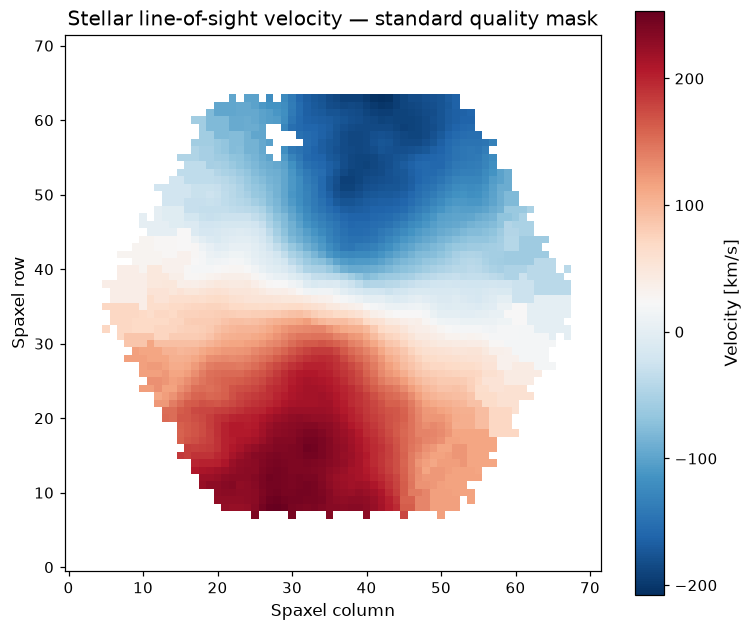

Saved: D:\KS\manga-stellar-kinematics\outputs\figures\stellar_velocity_map_standard.png


In [9]:
vel_plot = np.where(vel_valid_standard, vel, np.nan)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(vel_plot, origin="lower", cmap="RdBu_r")
ax.set_title("Stellar line-of-sight velocity — standard quality mask")
ax.set_xlabel("Spaxel column")
ax.set_ylabel("Spaxel row")
cbar = fig.colorbar(im, ax=ax)
cbar.set_label(f"Velocity [{maps['STELLAR_VEL'].header.get('BUNIT', 'unit not recorded')}]")
fig.tight_layout()
velocity_figure = FIGURES_DIR / "stellar_velocity_map_standard.png"
fig.savefig(velocity_figure, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", velocity_figure)

## 10. Plot the corrected stellar velocity-dispersion map

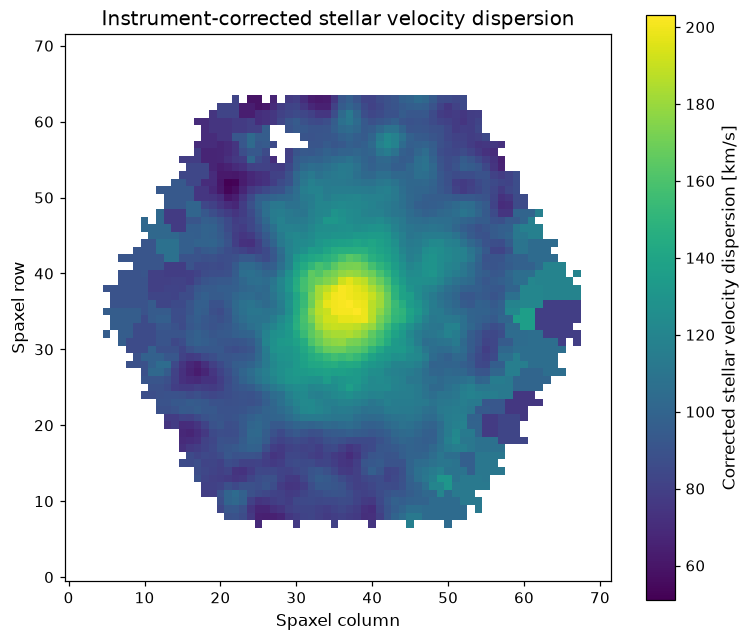

Saved: D:\KS\manga-stellar-kinematics\outputs\figures\stellar_sigma_corrected_map.png


In [10]:
sigma_plot = np.where(sigma_corr_valid_standard, sigma_corrected, np.nan)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(sigma_plot, origin="lower", cmap="viridis")
ax.set_title("Instrument-corrected stellar velocity dispersion")
ax.set_xlabel("Spaxel column")
ax.set_ylabel("Spaxel row")
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Corrected stellar velocity dispersion [km/s]")
fig.tight_layout()
sigma_figure = FIGURES_DIR / "stellar_sigma_corrected_map.png"
fig.savefig(sigma_figure, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", sigma_figure)

## 11. Compare standard and strict quality masks

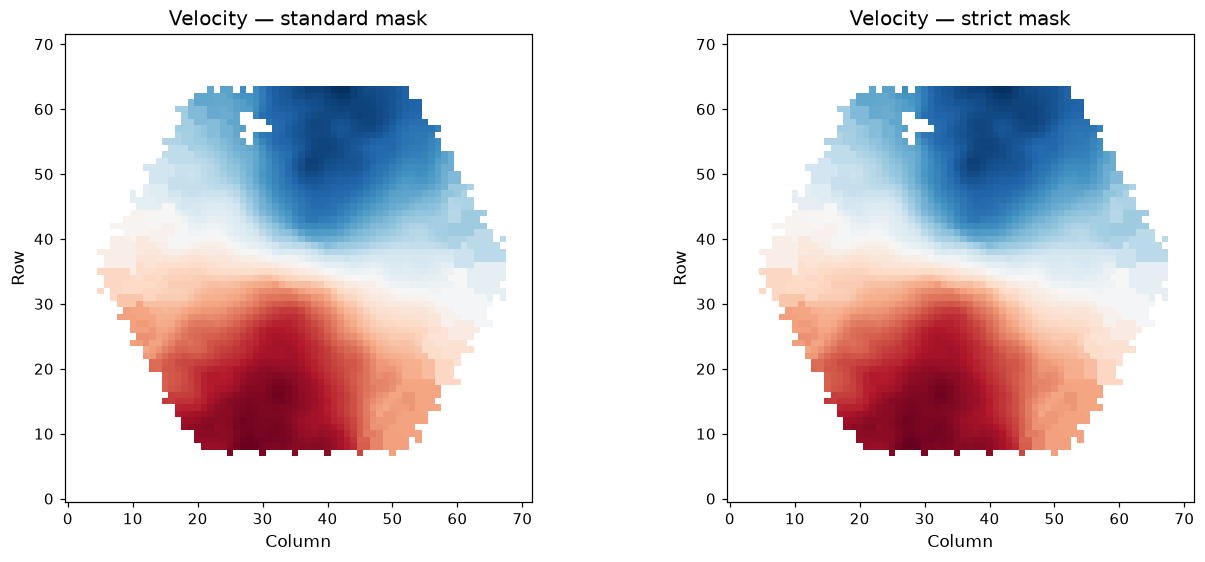

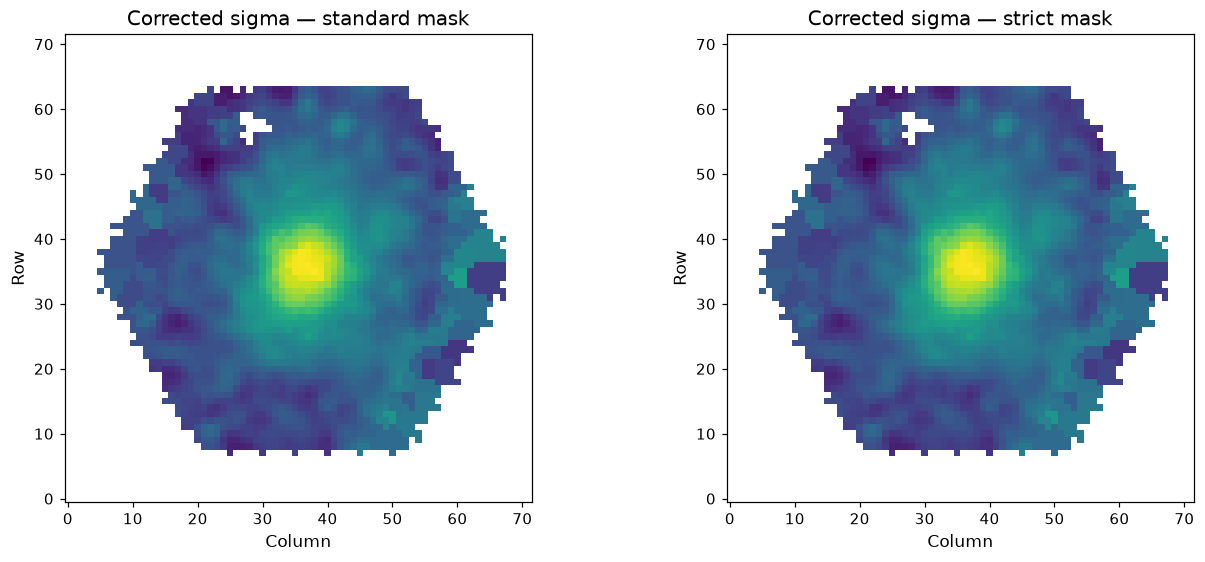

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

axes[0].imshow(np.where(vel_valid_standard, vel, np.nan),
               origin="lower", cmap="RdBu_r")
axes[0].set_title("Velocity — standard mask")
axes[0].set_xlabel("Column")
axes[0].set_ylabel("Row")

axes[1].imshow(np.where(vel_valid_strict, vel, np.nan),
               origin="lower", cmap="RdBu_r")
axes[1].set_title("Velocity — strict mask")
axes[1].set_xlabel("Column")
axes[1].set_ylabel("Row")

plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
axes[0].imshow(np.where(sigma_corr_valid_standard, sigma_corrected, np.nan),
               origin="lower", cmap="viridis")
axes[0].set_title("Corrected sigma — standard mask")
axes[0].set_xlabel("Column")
axes[0].set_ylabel("Row")

axes[1].imshow(np.where(sigma_corr_valid_strict, sigma_corrected, np.nan),
               origin="lower", cmap="viridis")
axes[1].set_title("Corrected sigma — strict mask")
axes[1].set_xlabel("Column")
axes[1].set_ylabel("Row")
plt.show()

## 12. Save extracted arrays for downstream analysis

In [12]:
output_npz = PROCESSED_DIR / "stellar_kinematics_8138-12704.npz"

np.savez_compressed(
    output_npz,
    stellar_velocity_raw=vel,
    stellar_velocity_ivar=vel_ivar,
    stellar_velocity_mask=vel_mask,
    stellar_velocity_valid_standard=vel_valid_standard,
    stellar_velocity_valid_strict=vel_valid_strict,
    stellar_sigma_raw=sigma_raw,
    stellar_sigma_ivar=sigma_ivar,
    stellar_sigma_mask=sigma_mask,
    stellar_sigma_instrumental_correction=sigma_inst,
    stellar_sigma_corrected=sigma_corrected,
    stellar_sigma_valid_standard=sigma_corr_valid_standard,
    stellar_sigma_valid_strict=sigma_corr_valid_strict,
)

print("Saved processed arrays:", output_npz)

Saved processed arrays: D:\KS\manga-stellar-kinematics\data\processed\stellar_kinematics_8138-12704.npz


## 13. Record a compact extraction report

In [13]:
report_path = PROJECT_ROOT / "outputs" / "stellar_kinematics_extraction_report.txt"

report_lines = [
    "MaNGA Stellar Kinematics Extraction Report",
    "Plate-IFU: 8138-12704",
    "DAPTYPE: HYB10-MILESHC-MASTARSSP",
    f"MAPS file: {MAPS_PATH.name}",
    f"Spatial shape: {vel.shape}",
    f"Velocity valid (standard): {vel_valid_standard.sum()} / {vel.size}",
    f"Velocity valid (strict): {vel_valid_strict.sum()} / {vel.size}",
    f"Corrected sigma valid (standard): {sigma_corr_valid_standard.sum()} / {vel.size}",
    f"Corrected sigma valid (strict): {sigma_corr_valid_strict.sum()} / {vel.size}",
    f"Negative sigma correction radicands: {np.sum(np.isfinite(sigma_squared_corrected) & (sigma_squared_corrected < 0))}",
    "Dispersion correction: sqrt(STELLAR_SIGMA**2 - STELLAR_SIGMACORR[0]**2)",
]
report_path.write_text("\n".join(report_lines), encoding="utf-8")
print(report_path.read_text(encoding="utf-8"))

MaNGA Stellar Kinematics Extraction Report
Plate-IFU: 8138-12704
DAPTYPE: HYB10-MILESHC-MASTARSSP
MAPS file: manga-8138-12704-MAPS-HYB10-MILESHC-MASTARSSP.fits.gz
Spatial shape: (72, 72)
Velocity valid (standard): 2704 / 5184
Velocity valid (strict): 2704 / 5184
Corrected sigma valid (standard): 2704 / 5184
Corrected sigma valid (strict): 2704 / 5184
Negative sigma correction radicands: 0
Dispersion correction: sqrt(STELLAR_SIGMA**2 - STELLAR_SIGMACORR[0]**2)


## 14. Close the FITS file

Run this after you have finished all analysis in this notebook.

In [14]:
maps.close()
print("MAPS FITS file closed.")

MAPS FITS file closed.


## 15. Milestone 3 completion checklist

- [ ] Required stellar kinematic extensions loaded successfully.
- [ ] Array shapes and units checked.
- [ ] DAP mask bits decoded using bitwise operations.
- [ ] Standard and strict quality masks generated.
- [ ] Instrument-corrected stellar velocity dispersion calculated.
- [ ] Velocity and corrected-dispersion maps inspected.
- [ ] Processed arrays and figures saved.

### Scientific cautions
- The velocity map is a **line-of-sight** velocity field, not a 3D velocity map.
- The corrected dispersion can be undefined where the instrumental correction exceeds the raw measured dispersion.
- A quality mask is not merely a NaN mask; individual flags have different meanings. Keep the raw arrays and masks.
- These maps alone do not establish the presence of a supermassive black-hole binary. That requires a separate, carefully justified dynamical analysis and supporting evidence.

**Next milestone:** spatial/WCS-aware visualization, galaxy center and geometry, then quantitative rotation and dispersion measurements.